In [2]:
# ── Cell 1: Imports & reproducibility ────────────────────────────────────────
import os, math, random, warnings
from pathlib import Path
import kagglehub

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2

warnings.filterwarnings('ignore')

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__} | Device: {DEVICE}')

PyTorch 2.10.0+cu128 | Device: cuda


In [3]:

path = kagglehub.competition_download('multimodal-cancer-classification-challenge-2026')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/multimodal-cancer-classification-challenge-2026


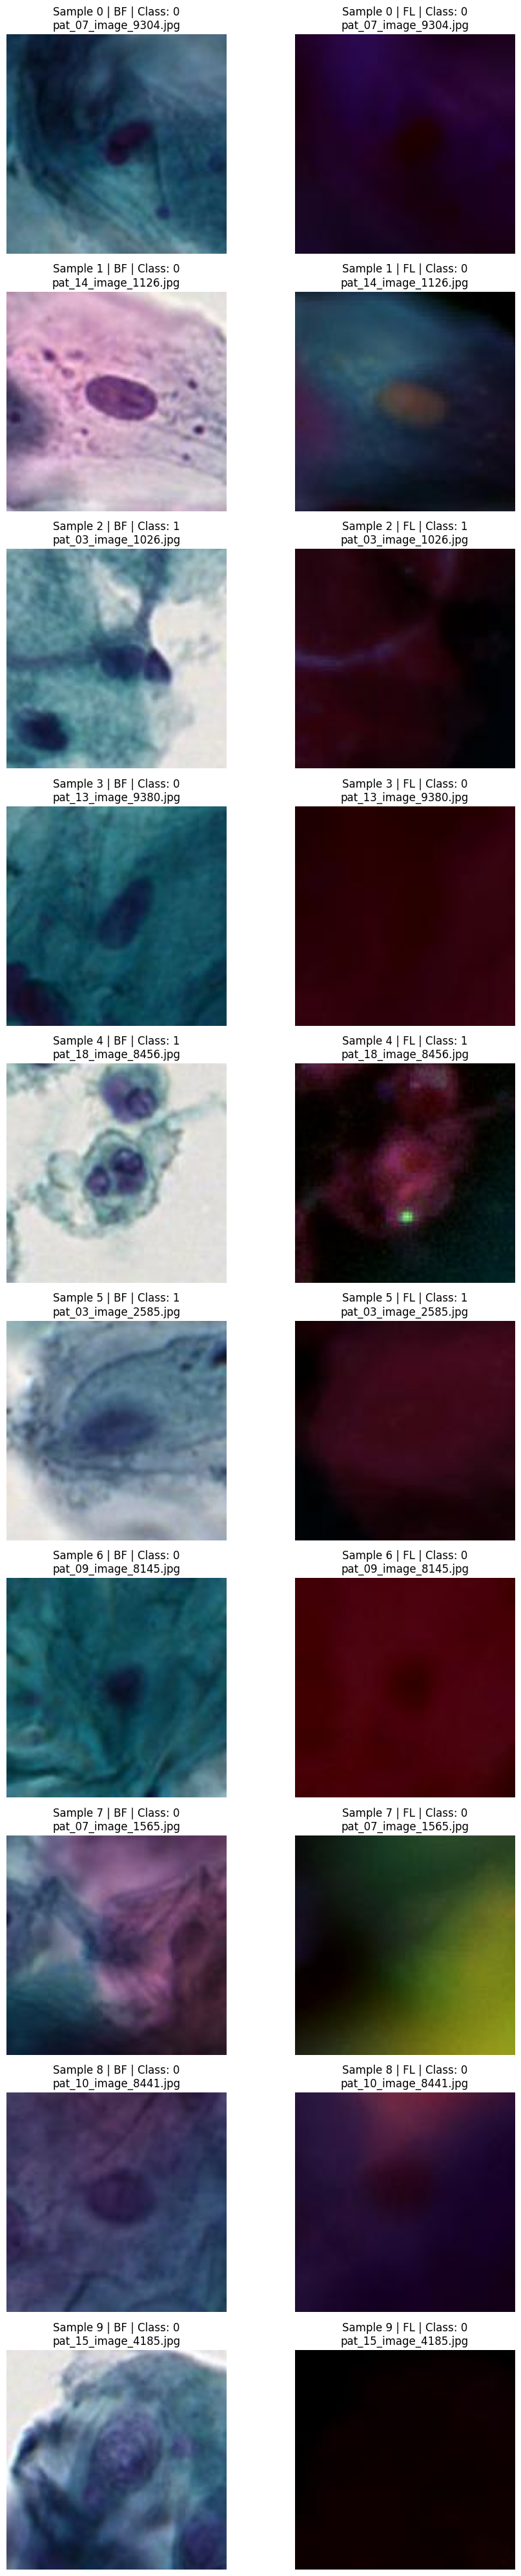

In [4]:

# 1. Correct base path to the input data directory
INPUT_DIR = "/kaggle/input/competitions/multimodal-cancer-classification-challenge-2026"

# Load the csv
df_train = pd.read_csv(os.path.join(INPUT_DIR, 'train.csv'))

# 2. Function using the correct path mapping: [Modality]/train/[Filename]
def plot_multimodal_samples(df, base_path, num_samples=10):
    fig, axes = plt.subplots(num_samples, 2, figsize=(10, 4 * num_samples))
    
    # Sample random cells from the tracking sheet
    samples = df.sample(num_samples, random_state=42).reset_index(drop=True)
    
    for i, row in samples.iterrows():
        img_name = row['Name']
        label = row['Diagnosis']
        
        # Include the 'train' subdirectory layer we discovered
        bf_path = os.path.join(base_path, 'BF', 'train', img_name)
        fl_path = os.path.join(base_path, 'FL', 'train', img_name)
        
        # --- Column 1: Brightfield (BF) ---
        if os.path.exists(bf_path):
            img_bf = Image.open(bf_path)
            axes[i, 0].imshow(img_bf, cmap='gray' if img_bf.mode == 'L' else None)
            axes[i, 0].set_title(f"Sample {i} | BF | Class: {label}\n{img_name}")
            axes[i, 0].axis('off')
        else:
            axes[i, 0].text(0.5, 0.5, f"BF File Not Found:\n{bf_path}", ha='center', va='center', color='red')
            axes[i, 0].axis('off')
            
        # --- Column 2: Fluorescence (FL) ---
        if os.path.exists(fl_path):
            img_fl = Image.open(fl_path)
            axes[i, 1].imshow(img_fl, cmap='gray' if img_fl.mode == 'L' else None)
            axes[i, 1].set_title(f"Sample {i} | FL | Class: {label}\n{img_name}")
            axes[i, 1].axis('off')
        else:
            axes[i, 1].text(0.5, 0.5, f"FL File Not Found:\n{fl_path}", ha='center', va='center', color='red')
            axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Run the correct path visualizer
plot_multimodal_samples(df_train, INPUT_DIR, num_samples=10)

In [5]:


INPUT_DIR = "/kaggle/input/competitions/multimodal-cancer-classification-challenge-2026"
df_train = pd.read_csv(os.path.join(INPUT_DIR, 'train.csv'))

# 1. Extract the patient ID group by grabbing the first two parts of the filename string
df_train['Patient_ID'] = df_train['Name'].apply(lambda x: "_".join(x.split('_')[:2]))

print("=== DATASET PROFILE AUDIT ===")
print(f"Total individual cell images : {df_train.shape[0]}")
print(f"Total unique patient sources : {df_train['Patient_ID'].nunique()}")
print(f"Average cells per patient    : {df_train.shape[0] / df_train['Patient_ID'].nunique():.1f}")

print("\n=== CLASS DISTRIBUTION (DIAGNOSIS) ===")
# Checks the ratio of healthy vs cancer rows (0 vs 1)
print(df_train['Diagnosis'].value_counts())
print("\nIn percentages:")
print(df_train['Diagnosis'].value_counts(normalize=True) * 100)

print("\n=== TOP 5 PATIENTS BY CELL COUNT ===")
print(df_train['Patient_ID'].value_counts().head(5))

=== DATASET PROFILE AUDIT ===
Total individual cell images : 114302
Total unique patient sources : 12
Average cells per patient    : 9525.2

=== CLASS DISTRIBUTION (DIAGNOSIS) ===
Diagnosis
0    70000
1    44302
Name: count, dtype: int64

In percentages:
Diagnosis
0    61.241273
1    38.758727
Name: proportion, dtype: float64

=== TOP 5 PATIENTS BY CELL COUNT ===
Patient_ID
pat_03    10000
pat_07    10000
pat_09    10000
pat_10    10000
pat_15    10000
Name: count, dtype: int64


In [6]:
# ── Cell 2: Paths & Config ────────────────────────────────────────────────────
INPUT_DIR = Path('/kaggle/input/competitions/multimodal-cancer-classification-challenge-2026')
OUTPUT_DIR = Path('/kaggle/working')
OUTPUT_DIR.mkdir(exist_ok=True)

CFG = dict(
    img_size      = 224,
    batch_size    = 64,       # per-cell batch; reduce to 32 if OOM
    num_epochs    = 20,
    lr            = 3e-4,
    weight_decay  = 1e-4,
    n_folds       = 4,
    # MIL bag settings
    bag_size      = 32,       # cells sampled per patient per iteration
    # Focal loss
    focal_alpha   = 0.75,
    focal_gamma   = 2.0,
    # AMP
    use_amp       = True,
    # TTA at inference
    tta_n         = 5,
)

print('Config loaded.')
print(CFG)

Config loaded.
{'img_size': 224, 'batch_size': 64, 'num_epochs': 20, 'lr': 0.0003, 'weight_decay': 0.0001, 'n_folds': 4, 'bag_size': 32, 'focal_alpha': 0.75, 'focal_gamma': 2.0, 'use_amp': True, 'tta_n': 5}


In [7]:
# ── Cell 3: Load metadata & engineer Patient ID ───────────────────────────────
df = pd.read_csv(INPUT_DIR / 'train.csv')

# Patient ID = first two underscore-separated tokens  (e.g. pat_03)
df['Patient_ID'] = df['Name'].apply(lambda x: '_'.join(x.split('_')[:2]))

# Full paths for both modalities
df['bf_path'] = df['Name'].apply(lambda x: str(INPUT_DIR / 'BF' / 'train' / x))
df['fl_path'] = df['Name'].apply(lambda x: str(INPUT_DIR / 'FL' / 'train' / x))

print(df.shape)
print(df['Diagnosis'].value_counts())
print(df['Patient_ID'].value_counts())

(114302, 5)
Diagnosis
0    70000
1    44302
Name: count, dtype: int64
Patient_ID
pat_03    10000
pat_07    10000
pat_09    10000
pat_10    10000
pat_15    10000
pat_11    10000
pat_13    10000
pat_14    10000
pat_17    10000
pat_16    10000
pat_18    10000
pat_05     4302
Name: count, dtype: int64


In [8]:
# ── Cell 4: Albumentations augmentation pipelines ─────────────────────────────
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_aug = A.Compose([
    A.RandomResizedCrop(size=(CFG['img_size'], CFG['img_size']), scale=(0.7, 1.0)),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=30, p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, fill_value=0, p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_aug = A.Compose([
    A.Resize(height=CFG['img_size'], width=CFG['img_size']),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

print('Augmentations ready.')

Augmentations ready.


In [9]:
# ── Cell 5: Dataset — dual-channel (BF + FL stacked as 6 channels) ────────────
#
# Strategy: load BF (RGB=3ch) and FL (RGB=3ch) → concatenate → 6-channel tensor.
# Each modality stream in the network sees its own 3 channels (split inside model).
# This is equivalent to "early feature extraction, late fusion".

class CancerCellDataset(Dataset):
    """
    Returns a 6-channel image: first 3 = BF, last 3 = FL.
    label = Diagnosis (0 or 1)
    """
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Load BF
        try:
            img_bf = np.array(Image.open(row['bf_path']).convert('RGB'))
        except Exception:
            img_bf = np.zeros((CFG['img_size'], CFG['img_size'], 3), dtype=np.uint8)

        # Load FL
        try:
            img_fl = np.array(Image.open(row['fl_path']).convert('RGB'))
        except Exception:
            img_fl = np.zeros((CFG['img_size'], CFG['img_size'], 3), dtype=np.uint8)

        if self.transform:
            # Apply SAME spatial transforms to both (use replay API)
            replay_data = self.transform(image=img_bf)
            img_bf_t    = replay_data['image']   # 3 x H x W

            # Re-apply same transform independently to FL
            # (intensity transforms differ on purpose; spatial must match)
            img_fl_t = self.transform(image=img_fl)['image']  # 3 x H x W
        else:
            # Minimal fallback
             to_tensor = A.Compose([
                A.Resize(height=CFG['img_size'], width=CFG['img_size']),
                A.Normalize(mean=MEAN, std=STD),
                ToTensorV2()
                ])

        # 6-channel stacked tensor
        img = torch.cat([img_bf_t, img_fl_t], dim=0)   # (6, H, W)
        label = torch.tensor(row['Diagnosis'], dtype=torch.float32)
        return img, label

print('Dataset class defined.')

Dataset class defined.


In [10]:
# ── Cell 6: ResNet-14 (lightweight, custom) ───────────────────────────────────
#
# Architecture: 4 stages × 2 blocks + global avg pool + head
# Input: 6-channel (BF+FL), split inside the model for dual-stream processing
#
# Dual-stream intermediate fusion:
#   - BF stream:  3ch → stage1 → stage2
#   - FL stream:  3ch → stage1 → stage2
#   - Fuse (concat + 1×1 conv) after stage 2
#   - Shared stage3 → stage4 → attention pool → classifier

class BasicBlock(nn.Module):
    """Standard 2-conv residual block."""
    expansion = 1

    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch,  out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1,      padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_ch)

        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )

    def forward(self, x):
        identity = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample:
            identity = self.downsample(x)
        return F.relu(out + identity)


def _make_layer(in_ch, out_ch, num_blocks, stride=1):
    layers = [BasicBlock(in_ch, out_ch, stride=stride)]
    for _ in range(1, num_blocks):
        layers.append(BasicBlock(out_ch, out_ch))
    return nn.Sequential(*layers)


class DualStreamResNet14(nn.Module):
    """
    ResNet-14 with dual-stream intermediate fusion.
    Each stream handles one imaging modality (BF or FL, each 3ch).
    Fusion happens after stage-2 via concat + 1×1 projection.
    """
    def __init__(self, num_classes=1, base_ch=64):
        super().__init__()
        # ── BF stream ─────────────────────────────────────────────────────────
        self.bf_stem   = nn.Sequential(
            nn.Conv2d(3, base_ch, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(base_ch), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1)
        )
        self.bf_stage1 = _make_layer(base_ch,      base_ch,      2, stride=1)
        self.bf_stage2 = _make_layer(base_ch,      base_ch * 2,  2, stride=2)

        # ── FL stream ─────────────────────────────────────────────────────────
        self.fl_stem   = nn.Sequential(
            nn.Conv2d(3, base_ch, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(base_ch), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1)
        )
        self.fl_stage1 = _make_layer(base_ch,      base_ch,      2, stride=1)
        self.fl_stage2 = _make_layer(base_ch,      base_ch * 2,  2, stride=2)

        # ── Fusion: concat (2 × 128ch) → project to 128ch ─────────────────────
        self.fusion = nn.Sequential(
            nn.Conv2d(base_ch * 4, base_ch * 2, 1, bias=False),
            nn.BatchNorm2d(base_ch * 2),
            nn.ReLU(inplace=True)
        )

        # ── Shared upper layers ────────────────────────────────────────────────
        self.stage3    = _make_layer(base_ch * 2,  base_ch * 4,  2, stride=2)
        self.stage4    = _make_layer(base_ch * 4,  base_ch * 8,  2, stride=2)

        self.gap = nn.AdaptiveAvgPool2d(1)

        # ── Classifier head ───────────────────────────────────────────────────
        self.head = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(base_ch * 8, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        """
        x: (B, 6, H, W)  — first 3ch = BF, last 3ch = FL
        """
        bf = x[:, :3, :, :]   # BF
        fl = x[:, 3:, :, :]   # FL

        # BF stream
        bf = self.bf_stage2(self.bf_stage1(self.bf_stem(bf)))

        # FL stream
        fl = self.fl_stage2(self.fl_stage1(self.fl_stem(fl)))

        # Fuse
        fused = self.fusion(torch.cat([bf, fl], dim=1))

        # Shared path
        out = self.stage4(self.stage3(fused))
        out = self.gap(out).flatten(1)
        return self.head(out)   # logits, shape (B, 1)


# Quick sanity check
_m = DualStreamResNet14().to(DEVICE)
_x = torch.randn(2, 6, 224, 224).to(DEVICE)
with torch.no_grad():
    _out = _m(_x)
print(f'Model output shape: {_out.shape}')   # should be (2, 1)
total_params = sum(p.numel() for p in _m.parameters())
print(f'Total parameters: {total_params:,}   (~{total_params/1e6:.1f}M)')
del _m, _x, _out

Model output shape: torch.Size([2, 1])
Total parameters: 12,024,193   (~12.0M)


In [11]:
# ── Cell 7: Focal Loss ────────────────────────────────────────────────────────

class FocalLoss(nn.Module):
    """
    Binary focal loss.
    alpha: weight for positive class (set > 0.5 when positives are minority)
    gamma: focusing parameter (2.0 is classic)
    """
    def __init__(self, alpha=0.75, gamma=2.0, reduction='mean'):
        super().__init__()
        self.alpha     = alpha
        self.gamma     = gamma
        self.reduction = reduction

    def forward(self, logits, targets):
        """logits: (B,1) or (B,), targets: (B,) float"""
        logits  = logits.view(-1)
        targets = targets.view(-1)
        bce     = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs   = torch.sigmoid(logits)
        pt      = targets * probs + (1 - targets) * (1 - probs)
        alpha_t = targets * self.alpha + (1 - targets) * (1 - self.alpha)
        loss    = alpha_t * (1 - pt) ** self.gamma * bce
        if self.reduction == 'mean':
            return loss.mean()
        return loss.sum()

print('FocalLoss defined.')

FocalLoss defined.


In [12]:
# ── Cell 8: Mixup augmentation ────────────────────────────────────────────────

def mixup_data(x, y, alpha=0.4):
    """Returns mixed inputs, pairs of targets, and lambda."""
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0
    batch_size = x.size(0)
    index = torch.randperm(batch_size, device=x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

print('Mixup helpers defined.')

Mixup helpers defined.


In [13]:
# ── Cell 9: Training & validation loops ──────────────────────────────────────

def train_one_epoch(model, loader, optimizer, criterion, scaler, device):
    model.train()
    total_loss = 0.0
    all_labels, all_preds = [], []

    for imgs, labels in tqdm(loader, leave=False, desc='  train'):
        imgs, labels = imgs.to(device), labels.to(device)

        # Mixup
        imgs, la, lb, lam = mixup_data(imgs, labels, alpha=0.4)

        optimizer.zero_grad()
        with autocast(enabled=CFG['use_amp']):
            logits = model(imgs).squeeze(1)     # (B,)
            loss   = mixup_criterion(criterion, logits, la, lb, lam)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * imgs.size(0)
        # For AUC tracking use un-mixed labels (la)
        all_labels.extend(la.cpu().numpy())
        all_preds.extend(torch.sigmoid(logits).detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    auc = roc_auc_score(all_labels, all_preds)
    return avg_loss, auc


@torch.no_grad()
def validate(model, loader, criterion, device, tta=False):
    model.eval()
    total_loss = 0.0
    all_labels, all_preds = [], []

    for imgs, labels in tqdm(loader, leave=False, desc='  val  '):
        imgs, labels = imgs.to(device), labels.to(device)

        if tta:
            # Average over N random augmented versions
            preds_tta = []
            for _ in range(CFG['tta_n']):
                with autocast(enabled=CFG['use_amp']):
                    logits = model(imgs).squeeze(1)
                preds_tta.append(torch.sigmoid(logits))
            logits_avg = torch.stack(preds_tta, 0).mean(0)  # average probs
            preds_out  = logits_avg
            loss_val   = criterion(torch.logit(logits_avg + 1e-6), labels)
        else:
            with autocast(enabled=CFG['use_amp']):
                logits = model(imgs).squeeze(1)
            loss_val   = criterion(logits, labels)
            preds_out  = torch.sigmoid(logits)

        total_loss += loss_val.item() * imgs.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds_out.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    auc = roc_auc_score(all_labels, all_preds)
    return avg_loss, auc


print('Train / validate loops defined.')

Train / validate loops defined.


In [ ]:
# ── Cell 10: 4-Fold Manual Stratified Training ───────────────────────────────
#
# WHY MANUAL FOLDS:
# With only 12 patients, StratifiedGroupKFold cannot guarantee both classes
# appear in every val set when multiple pure single-class patients exist.
# Manual round-robin assignment at the patient level is the only reliable fix.

# ── Step 1: Patient-level class profile ──────────────────────────────────────
patient_profile = df.groupby('Patient_ID').agg(
    total_cells    = ('Diagnosis', 'count'),
    malignant      = ('Diagnosis', 'sum'),
    benign         = ('Diagnosis', lambda x: (x == 0).sum()),
    unique_classes = ('Diagnosis', 'nunique')
).reset_index()

patient_profile['pct_malignant'] = (
    patient_profile['malignant'] / patient_profile['total_cells'] * 100
).round(1)

# Majority class label per patient (1 if >50% cells are malignant, else 0)
patient_profile['pat_label'] = (
    patient_profile['malignant'] / patient_profile['total_cells'] > 0.5
).astype(int)

print("=== Patient-Level Class Profile ===")
print(patient_profile[['Patient_ID', 'total_cells', 'malignant',
                        'benign', 'pct_malignant', 'unique_classes',
                        'pat_label']].to_string(index=False))

single_class = patient_profile[patient_profile['unique_classes'] == 1]
if len(single_class):
    print(f"\n⚠  Pure single-class patients detected: "
          f"{single_class['Patient_ID'].tolist()}")
else:
    print("\n✓  All patients have mixed-class cells.")

# ── Step 2: Separate patients by majority label ───────────────────────────────
malignant_pats = patient_profile[
    patient_profile['pat_label'] == 1]['Patient_ID'].tolist()
benign_pats    = patient_profile[
    patient_profile['pat_label'] == 0]['Patient_ID'].tolist()

print(f"\nMalignant-majority patients ({len(malignant_pats)}): {malignant_pats}")
print(f"Benign-majority    patients ({len(benign_pats)}):    {benign_pats}")

# ── Step 3: Shuffle each group with fixed seed ───────────────────────────────
random.seed(SEED)
random.shuffle(malignant_pats)
random.shuffle(benign_pats)

# ── Step 4: Round-robin assignment — each fold gets ≥1 from each class ───────
N_FOLDS = 4
folds   = []

for i in range(N_FOLDS):
    # Every 4th patient from each class list goes to this fold's val set
    val_mal      = malignant_pats[i::N_FOLDS]
    val_ben      = benign_pats[i::N_FOLDS]
    val_patients = val_mal + val_ben
    tr_patients  = [p for p in patient_profile['Patient_ID'].tolist()
                    if p not in val_patients]
    folds.append((tr_patients, val_patients))

# ── Step 5: Sanity check — verify both classes present in every val fold ──────
print("\n=== Fold Assignment Verification ===")
for i, (tr_pats, vl_pats) in enumerate(folds):
    vl_df     = df[df['Patient_ID'].isin(vl_pats)]
    tr_df     = df[df['Patient_ID'].isin(tr_pats)]
    vl_labels = vl_df['Diagnosis'].unique().tolist()
    overlap   = set(tr_pats) & set(vl_pats)   # must be empty
    print(f"Fold {i+1}:  "
          f"train_patients={tr_pats}  "
          f"val_patients={vl_pats}  "
          f"val_classes={sorted(vl_labels)}  "
          f"leakage={len(overlap) > 0}  "
          f"train_cells={len(tr_df):,}  "
          f"val_cells={len(vl_df):,}")
    assert len(overlap) == 0,   f"LEAKAGE in fold {i+1}!"
    assert len(vl_labels) == 2, f"Single-class val in fold {i+1}!"

print("\n✓  All folds passed: no leakage, both classes in every val set.")

# ── Step 6: Training loop ─────────────────────────────────────────────────────
best_fold_aucs = []
oof_preds      = np.zeros(len(df))

for fold, (tr_patients, vl_patients) in enumerate(folds):

    print(f"\n{'='*60}")
    print(f"  FOLD {fold+1}/{N_FOLDS}"
          f"  |  Train patients: {tr_patients}"
          f"  |  Val patients:   {vl_patients}")
    print(f"{'='*60}")

    df_train_fold = df[df['Patient_ID'].isin(tr_patients)].reset_index(drop=True)
    df_val_fold   = df[df['Patient_ID'].isin(vl_patients)].reset_index(drop=True)

    # ── Datasets ──────────────────────────────────────────────────────────────
    train_ds = CancerCellDataset(df_train_fold, transform=train_aug)
    val_ds   = CancerCellDataset(df_val_fold,   transform=val_aug)

    # ── Weighted sampler for class imbalance ──────────────────────────────────
    class_counts   = df_train_fold['Diagnosis'].value_counts().sort_index().values
    class_weights  = 1.0 / class_counts.astype(float)
    sample_weights = class_weights[df_train_fold['Diagnosis'].values]
    sampler = WeightedRandomSampler(
        weights     = torch.from_numpy(sample_weights).float(),
        num_samples = len(train_ds),
        replacement = True
    )

    train_loader = DataLoader(
        train_ds,
        batch_size  = CFG['batch_size'],
        sampler     = sampler,
        num_workers = 4,
        pin_memory  = True
    )
    val_loader = DataLoader(
        val_ds,
        batch_size  = CFG['batch_size'] * 2,
        shuffle     = False,
        num_workers = 4,
        pin_memory  = True
    )

    # ── Model / optimizer / scheduler ─────────────────────────────────────────
    model     = DualStreamResNet14(num_classes=1).to(DEVICE)
    criterion = FocalLoss(alpha=CFG['focal_alpha'], gamma=CFG['focal_gamma'])
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr           = CFG['lr'],
        weight_decay = CFG['weight_decay']
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=CFG['num_epochs'], eta_min=1e-6
    )
    scaler = GradScaler(enabled=CFG['use_amp'])

    best_val_auc   = 0.0
    best_ckpt_path = OUTPUT_DIR / f'best_fold{fold+1}.pt'

    # ── Epoch loop ────────────────────────────────────────────────────────────
    for epoch in range(CFG['num_epochs']):
        tr_loss, tr_auc = train_one_epoch(
            model, train_loader, optimizer, criterion, scaler, DEVICE
        )
        vl_loss, vl_auc = validate(
            model, val_loader, criterion, DEVICE, tta=False
        )
        scheduler.step()

        print(f"  Ep {epoch+1:02d}/{CFG['num_epochs']}  "
              f"tr_loss={tr_loss:.4f}  tr_auc={tr_auc:.4f}  "
              f"vl_loss={vl_loss:.4f}  vl_auc={vl_auc:.4f}  "
              f"lr={scheduler.get_last_lr()[0]:.2e}")

        if vl_auc > best_val_auc:
            best_val_auc = vl_auc
            torch.save(model.state_dict(), best_ckpt_path)
            print(f"    ✓ Saved best model  (val_auc={best_val_auc:.4f})")

    # ── OOF predictions with TTA using best checkpoint ────────────────────────
    print(f"\n  Loading best checkpoint for fold {fold+1}...")
    model.load_state_dict(torch.load(best_ckpt_path, map_location=DEVICE))
    model.eval()

    probs_list = []
    with torch.no_grad():
        for imgs, _ in tqdm(val_loader, leave=False, desc=f"  OOF TTA fold{fold+1}"):
            imgs       = imgs.to(DEVICE)
            tta_ps     = [
                torch.sigmoid(model(imgs).squeeze(1))
                for _ in range(CFG['tta_n'])
            ]
            batch_probs = torch.stack(tta_ps, dim=0).mean(dim=0)
            probs_list.extend(batch_probs.cpu().numpy())

    # Map probs back to their original positions in the full df
    val_global_idx            = df[df['Patient_ID'].isin(vl_patients)].index.values
    oof_preds[val_global_idx] = probs_list

    oof_auc = roc_auc_score(df_val_fold['Diagnosis'].values, probs_list)
    best_fold_aucs.append(oof_auc)
    print(f"  Fold {fold+1} OOF AUC (TTA): {oof_auc:.4f}")

# ── Final cross-validation summary ───────────────────────────────────────────
print(f"\n{'='*60}")
print(f"CV AUC per fold : {[f'{a:.4f}' for a in best_fold_aucs]}")
print(f"Mean CV AUC     : {np.mean(best_fold_aucs):.4f} "
      f"± {np.std(best_fold_aucs):.4f}")
print(f"Overall OOF AUC : {roc_auc_score(df['Diagnosis'].values, oof_preds):.4f}")

=== Patient-Level Class Profile ===
Patient_ID  total_cells  malignant  benign  pct_malignant  unique_classes  pat_label
    pat_03        10000      10000       0          100.0               1          1
    pat_05         4302       4302       0          100.0               1          1
    pat_07        10000          0   10000            0.0               1          0
    pat_09        10000          0   10000            0.0               1          0
    pat_10        10000          0   10000            0.0               1          0
    pat_11        10000          0   10000            0.0               1          0
    pat_13        10000          0   10000            0.0               1          0
    pat_14        10000          0   10000            0.0               1          0
    pat_15        10000          0   10000            0.0               1          0
    pat_16        10000      10000       0          100.0               1          1
    pat_17        10000      

  train:   0%|          | 0/1161 [00:00<?, ?it/s]

  val  :   0%|          | 0/313 [00:00<?, ?it/s]

  Ep 01/20  tr_loss=0.0492  tr_auc=0.7222  vl_loss=0.0771  vl_auc=0.7356  lr=2.98e-04
    ✓ Saved best model  (val_auc=0.7356)


  train:   0%|          | 0/1161 [00:00<?, ?it/s]

...

  Ep 08/20  tr_loss=0.0438  tr_auc=0.7271  vl_loss=0.0249  vl_auc=0.9896  lr=1.97e-04
    ✓ Saved best model  (val_auc=0.9896)


  train:   0%|          | 0/1474 [00:00<?, ?it/s]

  val  :   0%|          | 0/157 [00:00<?, ?it/s]

  Ep 09/20  tr_loss=0.0430  tr_auc=0.7441  vl_loss=0.0299  vl_auc=0.9783  lr=1.74e-04


  train:   0%|          | 0/1474 [00:00<?, ?it/s]

In [ ]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

# ROC curve
fpr, tpr, _ = roc_curve(df['Diagnosis'].values, oof_preds)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, label=f'OOF AUC = {roc_auc_score(df["Diagnosis"].values, oof_preds):.4f}')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('OOF ROC Curve'); plt.legend()

# Per-patient score distribution
plt.subplot(1, 2, 2)
df['oof_pred'] = oof_preds
pat_scores = df.groupby('Patient_ID').agg(
    mean_pred = ('oof_pred', 'mean'),
    label     = ('Diagnosis', 'first')
).reset_index()
colors = ['blue' if l == 0 else 'red' for l in pat_scores['label']]
plt.bar(pat_scores['Patient_ID'], pat_scores['mean_pred'], color=colors)
plt.axhline(0.5, color='black', linestyle='--')
plt.xticks(rotation=45)
plt.title('Mean OOF Prediction per Patient\n(red=malignant, blue=benign)')
plt.tight_layout()
plt.show()

In [ ]:


# Build test dataframe
df_test = pd.DataFrame()
bf_test_dir = INPUT_DIR / 'BF' / 'test'
test_files  = sorted(bf_test_dir.glob('*.png'))   # adjust extension if needed
if not test_files:
    test_files = sorted(bf_test_dir.glob('*.jpg'))
if not test_files:
    test_files = sorted(bf_test_dir.glob('*.*'))   # fallback

df_test['Name']    = [f.name for f in test_files]
df_test['bf_path'] = [str(INPUT_DIR / 'BF' / 'test' / f.name) for f in test_files]
df_test['fl_path'] = [str(INPUT_DIR / 'FL' / 'test' / f.name) for f in test_files]
df_test['Diagnosis'] = 0   # placeholder

print(f'Test samples: {len(df_test)}')

# Dataset + loader for test
test_ds = CancerCellDataset(df_test, transform=val_aug)
test_loader = DataLoader(
    test_ds, batch_size=CFG['batch_size'] * 2,
    shuffle=False, num_workers=4, pin_memory=True
)

# Ensemble predictions
fold_test_preds = []

for fold in range(CFG['n_folds']):
    ckpt_path = OUTPUT_DIR / f'best_fold{fold+1}.pt'
    model = DualStreamResNet14(num_classes=1).to(DEVICE)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()

    fold_probs = []
    with torch.no_grad():
        for imgs, _ in tqdm(test_loader, leave=False, desc=f'  Fold {fold+1} TTA'):
            imgs = imgs.to(DEVICE)
            tta_ps = [torch.sigmoid(model(imgs).squeeze(1))
                      for _ in range(CFG['tta_n'])]
            fold_probs.extend(torch.stack(tta_ps, 0).mean(0).cpu().numpy())

    fold_test_preds.append(fold_probs)
    print(f'  Fold {fold+1} done.')

# Average across folds
ensemble_preds = np.mean(fold_test_preds, axis=0)

# ── Build submission ──────────────────────────────────────────────────────────
submission = pd.DataFrame({
    'Name':      df_test['Name'].values,
    'Diagnosis': ensemble_preds
})
submission.to_csv(OUTPUT_DIR / 'submission.csv', index=False)
print('submission.csv saved.')
submission.head()